In [26]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [27]:
def make_model():
  return nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 50), nn.ReLU(),
    nn.Linear(50, 50), nn.ReLU(),
    nn.Linear(50, 50), nn.ReLU(),
    nn.Linear(50, 10),
  ).to(device)

def interval_linear(l, u, W, b):
  c, r = (u + l) / 2, (u - l) / 2
  c = c @ W.t() + b
  r = r @ W.abs().t()
  return c - r, c + r

def hidden_bounds(model, x, eps):
  l = (x - eps).clamp(0, 1).view(-1, 784)
  u = (x + eps).clamp(0, 1).view(-1, 784)
  linears = [m for m in model if isinstance(m, nn.Linear)]
  for layer in linears[:-1]:
    l, u = interval_linear(l, u, layer.weight, layer.bias)
    l, u = F.relu(l), F.relu(u)
  return l, u, linears[-1]

def worst_case_logits(model, x, y, eps):
  l, u, last = hidden_bounds(model, x, eps)
  W = last.weight.unsqueeze(0) - last.weight[y].unsqueeze(1)
  b = last.bias.unsqueeze(0) - last.bias[y].unsqueeze(1)
  c, r = (u + l) / 2, (u - l) / 2
  return torch.einsum('bkj,bj->bk', W, c) + torch.einsum('bkj,bj->bk', W.abs(), r) + b

def box_verify(model, x, y, eps):
  z_hat = worst_case_logits(model, x, y, eps)
  z_hat[torch.arange(len(y)), y] = -float('inf')
  return z_hat.max(1).values < 0

In [28]:
EPOCHS, WARMUP, RAMP = 20, 1, 10
EPS_TRAIN = 0.1

def ramp(t):
  return min(max((t - WARMUP) / RAMP, 0.0), 1.0)

def kappa(t):
  return 1.0 - 0.5 * ramp(t)
def eps_train(t):
  return EPS_TRAIN * ramp(t)

def standard_loss(model, x, y, t):
  return F.cross_entropy(model(x), y)

def ibp_loss(model, x, y, t):
  k = kappa(t)
  loss = F.cross_entropy(model(x), y)
  if k == 1.0:
    return loss
  z_hat = worst_case_logits(model, x, y, eps_train(t))
  return k * loss + (1 - k) * F.cross_entropy(z_hat, y)

def train(model, loss_fn):
  opt = optim.Adam(model.parameters(), lr=1e-3)
  start = time.time()
  for epoch in range(EPOCHS):
    model.train()
    for i, (x, y) in enumerate(train_loader):
      x, y = x.to(device), y.to(device)
      loss = loss_fn(model, x, y, epoch + i / len(train_loader))
      opt.zero_grad()
      loss.backward()
      opt.step()
    print(f'epoch {epoch + 1}: loss {loss.item():.3f}, time {time.time() - start:.0f} s')
  return time.time() - start

In [29]:
torch.manual_seed(0)
std_model = make_model()
std_time = train(std_model, standard_loss)

epoch 1: loss 0.027, time 8 s
epoch 2: loss 0.258, time 16 s
epoch 3: loss 0.122, time 26 s
epoch 4: loss 0.253, time 35 s
epoch 5: loss 0.041, time 44 s
epoch 6: loss 0.069, time 52 s
epoch 7: loss 0.039, time 61 s
epoch 8: loss 0.014, time 69 s
epoch 9: loss 0.006, time 77 s
epoch 10: loss 0.125, time 86 s
epoch 11: loss 0.103, time 94 s
epoch 12: loss 0.093, time 102 s
epoch 13: loss 0.009, time 110 s
epoch 14: loss 0.033, time 118 s
epoch 15: loss 0.002, time 127 s
epoch 16: loss 0.001, time 135 s
epoch 17: loss 0.022, time 143 s
epoch 18: loss 0.003, time 152 s
epoch 19: loss 0.001, time 159 s
epoch 20: loss 0.005, time 168 s


In [30]:
torch.manual_seed(0)
ibp_model = make_model()
ibp_time = train(ibp_model, ibp_loss)

epoch 1: loss 0.027, time 8 s
epoch 2: loss 0.345, time 19 s
epoch 3: loss 0.342, time 30 s
epoch 4: loss 0.441, time 41 s
epoch 5: loss 0.317, time 51 s
epoch 6: loss 0.366, time 62 s
epoch 7: loss 0.300, time 73 s
epoch 8: loss 0.176, time 84 s
epoch 9: loss 0.500, time 95 s
epoch 10: loss 0.262, time 106 s
epoch 11: loss 0.854, time 117 s
epoch 12: loss 0.803, time 128 s
epoch 13: loss 0.422, time 139 s
epoch 14: loss 0.840, time 150 s
epoch 15: loss 0.654, time 161 s
epoch 16: loss 0.519, time 172 s
epoch 17: loss 0.381, time 184 s
epoch 18: loss 0.534, time 195 s
epoch 19: loss 0.416, time 207 s
epoch 20: loss 0.462, time 219 s


In [31]:
def pgd(model, x, y, eps, steps=50):
  alpha = 2.5 * eps / steps
  x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
  for _ in range(steps):
    x_adv.requires_grad_(True)
    loss = F.cross_entropy(model(x_adv), y)
    grad, = torch.autograd.grad(loss, x_adv)
    x_adv = x_adv.detach() + alpha * grad.sign()
    x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
  return x_adv.detach()

def accuracy(model, eps=None):
  model.eval()
  correct = 0
  for x, y in test_loader:
    x, y = x.to(device), y.to(device)
    if eps is not None:
      x = pgd(model, x, y, eps)
    with torch.no_grad():
      correct += (model(x).argmax(1) == y).sum().item()
  return 100 * correct / len(test_dataset)

print(f"{'model':<10}{'acc':>14}{'PGD acc':>15}{'train time':>12}")
for name, model, sec in [('standard', std_model, std_time), ('IBP', ibp_model, ibp_time)]:
  print(f"{name:<10}{accuracy(model):>13.2f}%{accuracy(model, 0.1):>14.2f}%{sec:>11.1f}s")

model                acc        PGD acc  train time
standard          97.16%          2.00%      167.8s
IBP               94.91%         84.89%      219.1s


In [32]:
torch.manual_seed(0)
epsilons = np.linspace(0.01, 0.1, 10)
examples = {}
ibp_model.eval()

print(f"{'eps':>5}{'verified':>10}{'clean err':>11}{'adv found':>11}{'undecided':>11}")
for k, eps in enumerate(epsilons):
  n_ver, n_err, n_adv, n_unver = 0, 0, 0, 0
  examples[k] = []
  for x, y in test_loader:
    x, y = x.to(device), y.to(device)
    with torch.no_grad():
      correct = ibp_model(x).argmax(1) == y
      ver = box_verify(ibp_model, x, y, eps)
    n_ver += ver.sum().item()
    n_err += (~correct).sum().item()
    n_unver += (~ver).sum().item()

    attack = ~ver & correct
    if attack.any():
      xs, ys = x[attack], y[attack]
      x_adv = pgd(ibp_model, xs, ys, eps)
      with torch.no_grad():
        pred = ibp_model(x_adv).argmax(1)
      found = pred != ys
      n_adv += found.sum().item()
      examples[k] += list(zip(xs[found].cpu(), x_adv[found].cpu(), ys[found].cpu(), pred[found].cpu()))
  undecided = n_unver - n_err - n_adv
  print(f"{eps:>5.2f}{100 * n_ver / len(test_dataset):>9.2f}%{n_err:>11}{n_adv:>11}{undecided:>11}")

  eps  verified  clean err  adv found  undecided
 0.01    94.20%        509         64          7
 0.02    93.26%        509        131         34
 0.03    92.44%        509        202         45
 0.04    91.39%        509        273         79
 0.05    90.22%        509        361        108
 0.06    88.71%        509        456        164
 0.07    87.20%        509        563        208
 0.08    85.09%        509        691        291
 0.09    82.55%        509        849        387
 0.10    79.77%        509       1003        511


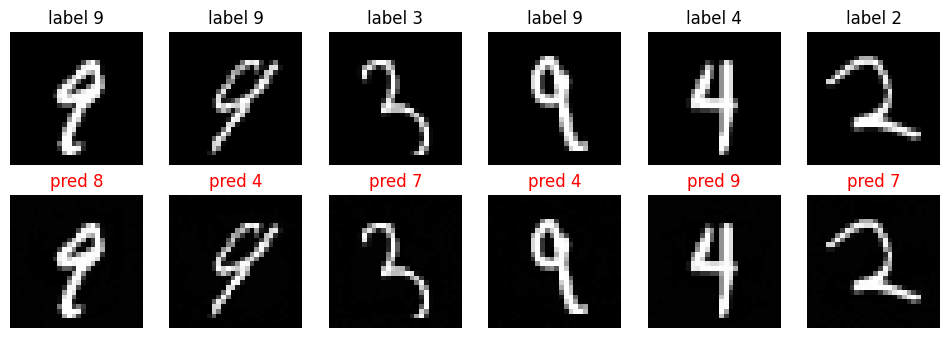

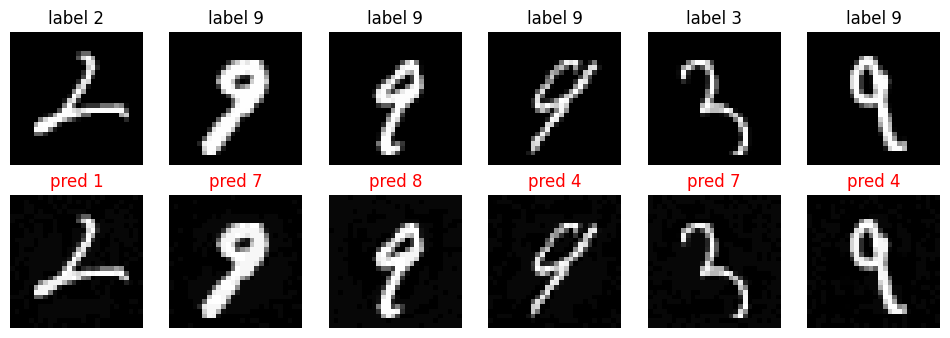

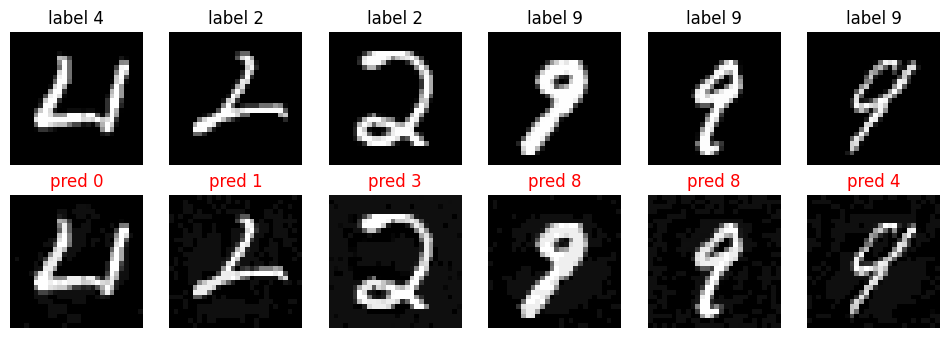

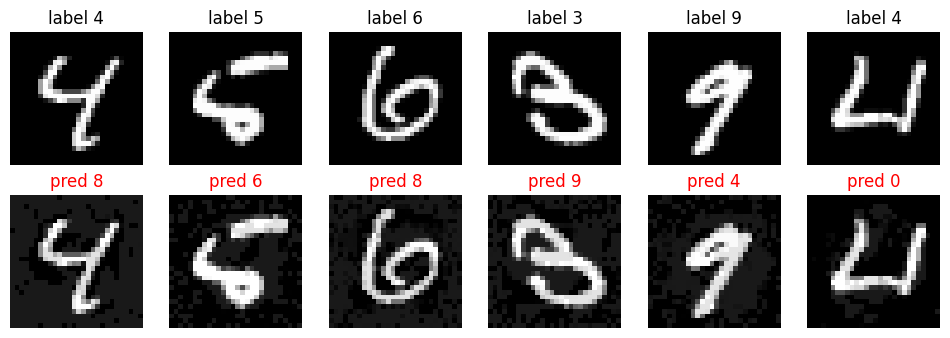

In [33]:
for k in [0, 2, 5, 9]:
    eps = epsilons[k]
    plt.figure(figsize=(12, 6))
    for i, (x, x_adv, y, p) in enumerate(examples[k][:6]):
        plt.subplot(3, 6, i + 1)
        plt.imshow(x.squeeze().cpu(), cmap='gray', vmin=0, vmax=1)
        plt.title(f'label {y.item()}')
        plt.axis('off')

        plt.subplot(3, 6, i + 7)
        plt.imshow(x_adv.squeeze().cpu(), cmap='gray', vmin=0, vmax=1)
        plt.title(f'pred {p.item()}', color='red')
        plt.axis('off')
    plt.show()